# Hotel Booking Demand — Complete Machine Learning Capstone
### EDA • Cleaning & Preprocessing • Regression • Classification • Clustering • Questions & Answers

**Dataset:** Hotel Booking Demand (`hotel_bookings.csv`)

**This single notebook covers the full project workflow:**
1. Data inspection and exploratory data analysis (EDA)
2. Data cleaning and preprocessing, with Before/After evidence
3. Regression — predict `adr` using Linear Regression
4. Classification — predict `is_canceled` using Logistic Regression
5. Clustering — group bookings using K-Means without using the target label
6. Ten useful dataset questions with answers generated from the uploaded data

> **Important:** Run the notebook from top to bottom. The code keeps an untouched copy named `df_raw`. Data transformations are performed on working copies. Model preprocessing is fitted on training data only to reduce data leakage. Some modelling sections use selected features rather than every column; the reasons are explained in the relevant sections.

## 0. Imports and display settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score,
    silhouette_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
RANDOM_STATE = 42


## 1. Load the dataset

## 2. Initial inspection (EDA)

In [3]:
import pandas as pd
import numpy as np

file_path = "/content/hotel_bookings.csv"

df_raw = pd.read_csv(file_path)
df = df_raw.copy()

print(f"File: {file_path}")
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")

display(df_raw.head())

File: /content/hotel_bookings.csv
Rows: 119,390
Columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
print("Dataset shape:", df_raw.shape)
print("\\nData types and non-null counts:")
df_raw.info()


Dataset shape: (119390, 32)
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies          

In [5]:
display(df_raw.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


### 2.1 Missing values — BEFORE cleaning

,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


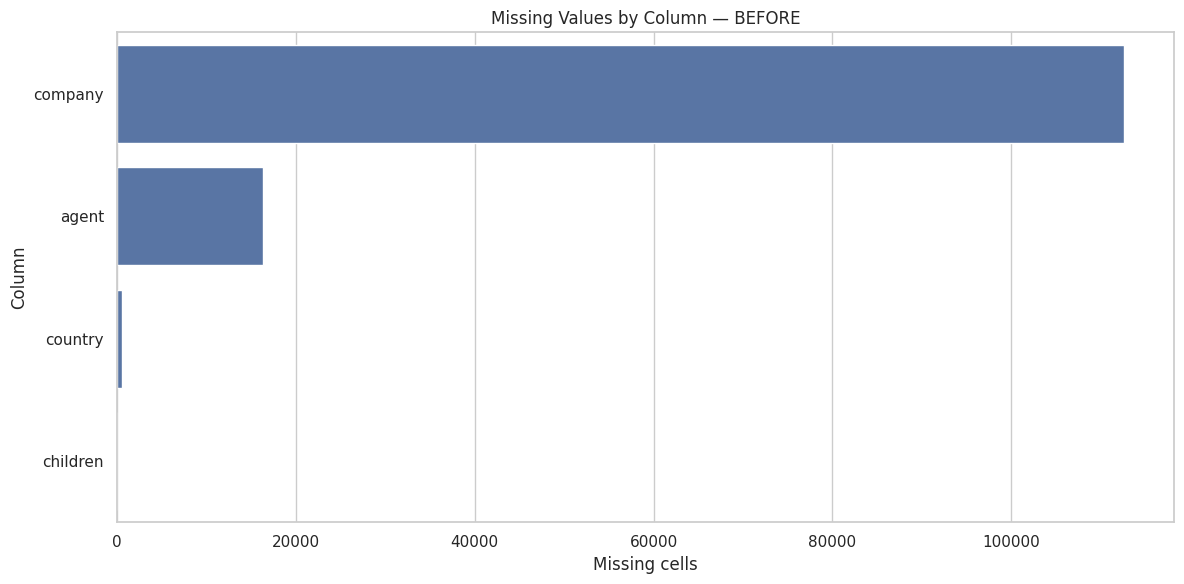

In [6]:
missing_before = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": df_raw.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

display(missing_before[missing_before.missing_count > 0].round(2))

missing_plot = missing_before[missing_before.missing_count > 0].reset_index(names="column")
plt.figure(figsize=(12, 6))
sns.barplot(data=missing_plot, x="missing_count", y="column")
plt.title("Missing Values by Column — BEFORE")
plt.xlabel("Missing cells")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


### 2.2 Exact duplicate rows — BEFORE cleaning

Exact duplicate rows: 31,994 (26.80%)


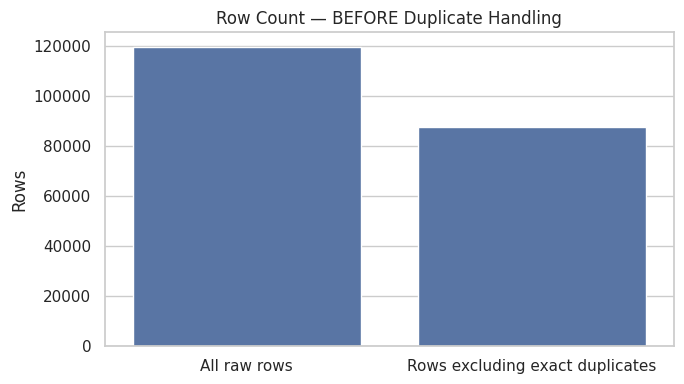

In [7]:
duplicates_before = int(df_raw.duplicated().sum())
print(f"Exact duplicate rows: {duplicates_before:,} ({duplicates_before/len(df_raw):.2%})")

plt.figure(figsize=(7, 4))
sns.barplot(x=["All raw rows", "Rows excluding exact duplicates"],
            y=[len(df_raw), len(df_raw) - duplicates_before])
plt.title("Row Count — BEFORE Duplicate Handling")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()


### 2.3 Numerical distributions and potential outliers

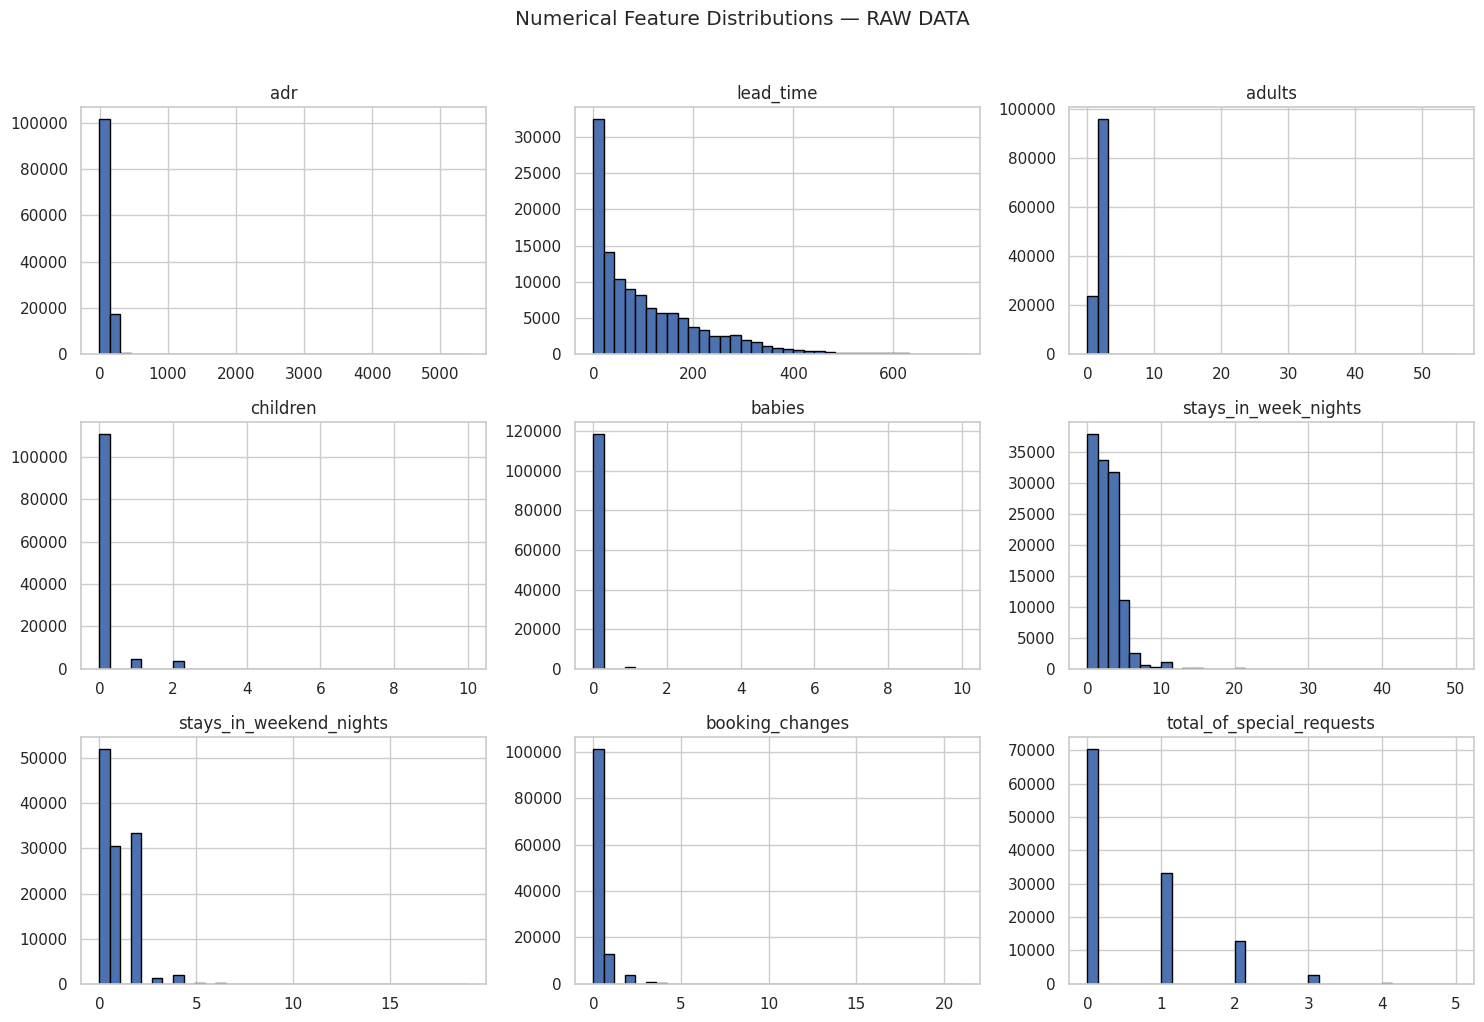

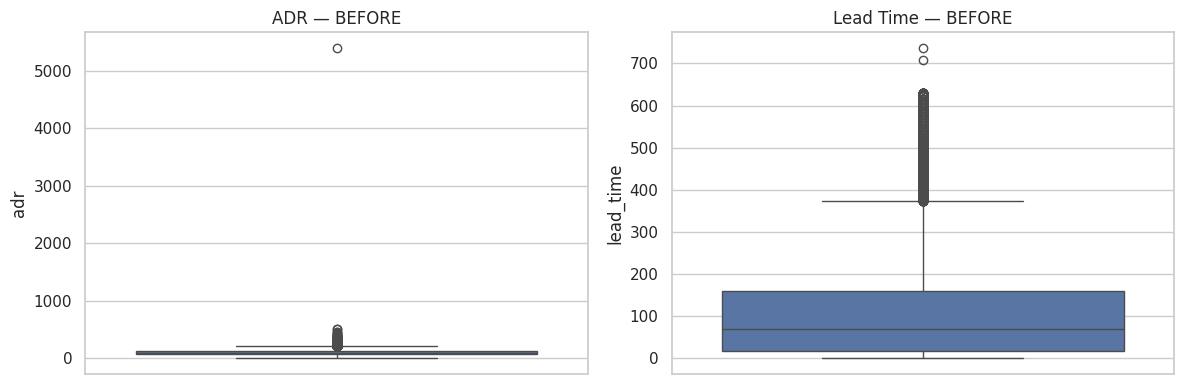

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
adr,119390.0,101.831122,50.535790,-6.38,0.0,69.29,94.575,126.0,193.5,252.0,5400.0
lead_time,119390.0,104.011416,106.863097,0.00,0.0,18.00,69.000,160.0,320.0,444.0,737.0


In [8]:
numeric_for_eda = [c for c in [
    "adr", "lead_time", "adults", "children", "babies",
    "stays_in_week_nights", "stays_in_weekend_nights",
    "booking_changes", "total_of_special_requests"
] if c in df_raw.columns]

df_raw[numeric_for_eda].hist(figsize=(15, 10), bins=35, edgecolor="black")
plt.suptitle("Numerical Feature Distributions — RAW DATA", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df_raw["adr"], ax=axes[0])
axes[0].set_title("ADR — BEFORE")
sns.boxplot(y=df_raw["lead_time"], ax=axes[1])
axes[1].set_title("Lead Time — BEFORE")
plt.tight_layout()
plt.show()

display(df_raw[["adr", "lead_time"]].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)


### 2.4 Target distribution for classification

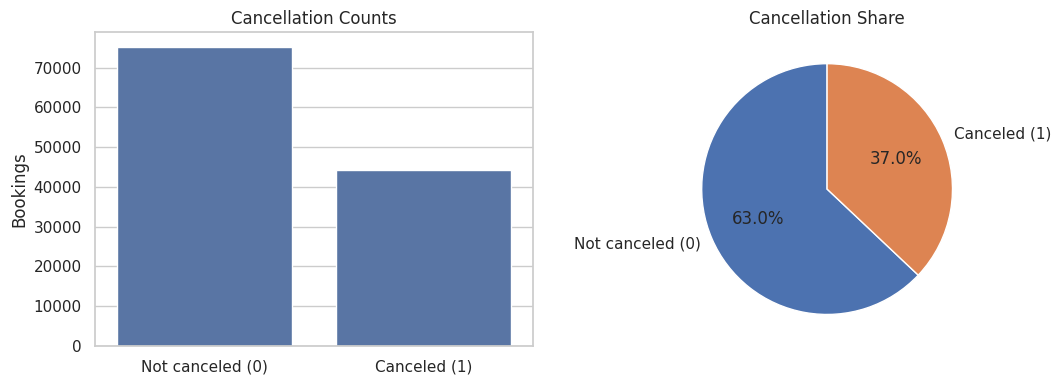

,count,percentage
is_canceled,,
0,75166,62.96
1,44224,37.04


In [9]:
cancel_counts = df_raw["is_canceled"].value_counts().sort_index()
cancel_labels = ["Not canceled (0)", "Canceled (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=cancel_labels, y=[cancel_counts.get(0,0), cancel_counts.get(1,0)], ax=axes[0])
axes[0].set_title("Cancellation Counts")
axes[0].set_ylabel("Bookings")
axes[1].pie([cancel_counts.get(0,0), cancel_counts.get(1,0)],
            labels=cancel_labels, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Cancellation Share")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "count": cancel_counts,
    "percentage": cancel_counts / len(df_raw) * 100
}).round(2))


### 2.5 A first business question: cancellation rate by hotel

,cancellation_rate_percent
hotel,
City Hotel,41.73
Resort Hotel,27.76


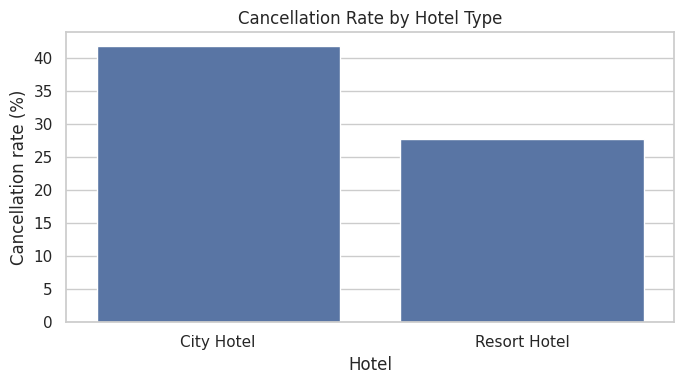

In [10]:
cancel_by_hotel = (df_raw.groupby("hotel")["is_canceled"]
                   .mean().mul(100).sort_values(ascending=False))
display(cancel_by_hotel.rename("cancellation_rate_percent").round(2))

plt.figure(figsize=(7,4))
sns.barplot(x=cancel_by_hotel.index, y=cancel_by_hotel.values)
plt.title("Cancellation Rate by Hotel Type")
plt.ylabel("Cancellation rate (%)")
plt.xlabel("Hotel")
plt.tight_layout()
plt.show()


## 3. Data cleaning and preprocessing — with BEFORE/AFTER evidence

### Decisions used in this notebook
- **Exact duplicates:** remove exact duplicate rows from the working dataset. We retain `df_raw` so the original is always available. In a real booking system, identical-looking rows should be checked against a unique booking ID before deletion; this public dataset does not provide one.
- **Invalid ADR:** negative `adr` values are treated as invalid and changed to missing. Very high positive ADR values are not automatically deleted; we will inspect them and use a robust target range for the regression task only if justified.
- **Missing values:** for model inputs, numeric values will be imputed with the median and categorical values with the most frequent category inside each training pipeline. This means imputation is learned from training data only.
- **High-missing columns:** `company` and `agent` are excluded from modelling in this version because they contain many missing values and can add high-cardinality identifiers. Their missingness remains documented in EDA.
- **Categorical values:** one-hot encoded inside the modelling pipelines.
- **Scaling:** numerical features are standardized inside the pipelines. The clustering features are also scaled before K-Means.

We do not globally impute every column or scale the entire dataset before splitting, because that can cause data leakage.

In [11]:
# Create a cleaned analysis copy
df_clean = df_raw.drop_duplicates().copy()
rows_after_duplicates = len(df_clean)

# Turn negative ADR values into missing values; keep zero and positive values.
negative_adr_count = int((df_clean["adr"] < 0).sum())
df_clean.loc[df_clean["adr"] < 0, "adr"] = np.nan

print(f"Rows before duplicate removal: {len(df_raw):,}")
print(f"Exact duplicates removed: {duplicates_before:,}")
print(f"Rows after duplicate removal: {len(df_clean):,}")
print(f"Negative ADR values converted to missing: {negative_adr_count:,}")


Rows before duplicate removal: 119,390
Exact duplicates removed: 31,994
Rows after duplicate removal: 87,396
Negative ADR values converted to missing: 1


### 3.1 Duplicates — BEFORE vs AFTER

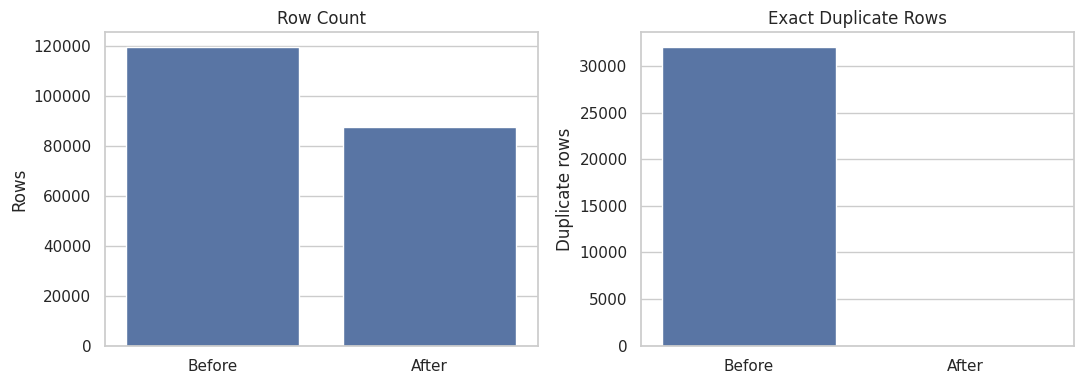

Remaining exact duplicates: 0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.barplot(x=["Before", "After"], y=[len(df_raw), len(df_clean)], ax=axes[0])
axes[0].set_title("Row Count")
axes[0].set_ylabel("Rows")
sns.barplot(x=["Before", "After"], y=[duplicates_before, int(df_clean.duplicated().sum())], ax=axes[1])
axes[1].set_title("Exact Duplicate Rows")
axes[1].set_ylabel("Duplicate rows")
plt.tight_layout()
plt.show()

print("Remaining exact duplicates:", df_clean.duplicated().sum())


### 3.2 Invalid ADR — BEFORE vs AFTER

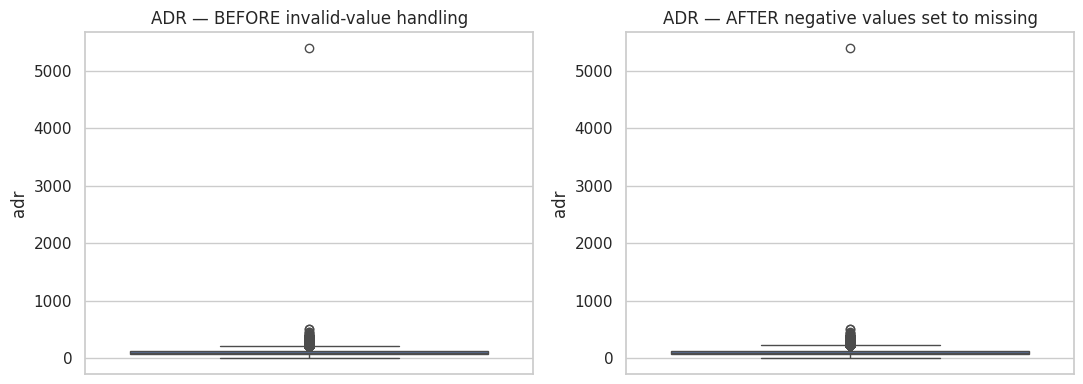

Negative ADR before: 1
Negative ADR after: 0
Missing ADR after: 1


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.boxplot(y=df_raw["adr"], ax=axes[0])
axes[0].set_title("ADR — BEFORE invalid-value handling")
sns.boxplot(y=df_clean["adr"], ax=axes[1])
axes[1].set_title("ADR — AFTER negative values set to missing")
plt.tight_layout()
plt.show()

print("Negative ADR before:", int((df_raw["adr"] < 0).sum()))
print("Negative ADR after:", int((df_clean["adr"] < 0).sum()))
print("Missing ADR after:", int(df_clean["adr"].isna().sum()))


### 3.3 Missing values — raw data vs cleaned modelling copy

The cleaning copy still contains missing values. This is intentional: the model pipelines will impute missing input values after the train/test split, using training-set statistics only.

,before,after_cleaning_copy
company,112593,82137
agent,16340,12193
country,488,452
children,4,4
adr,0,1


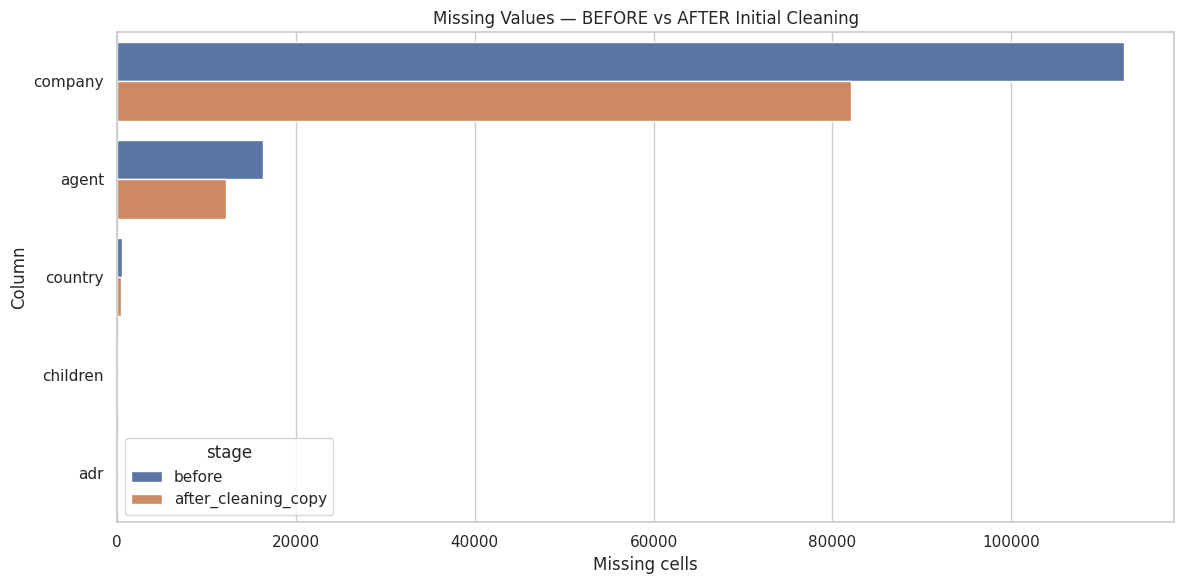

In [14]:
missing_after = pd.DataFrame({
    "before": df_raw.isna().sum(),
    "after_cleaning_copy": df_clean.isna().sum()
})
missing_compare = missing_after[
    (missing_after["before"] > 0) | (missing_after["after_cleaning_copy"] > 0)
].sort_values("before", ascending=False)

display(missing_compare.head(15))

plot_missing = missing_compare.head(10).reset_index(names="column").melt(
    id_vars="column", var_name="stage", value_name="missing_count"
)
plt.figure(figsize=(12,6))
sns.barplot(data=plot_missing, x="missing_count", y="column", hue="stage")
plt.title("Missing Values — BEFORE vs AFTER Initial Cleaning")
plt.xlabel("Missing cells")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


### 3.4 Feature scaling demonstration — BEFORE vs AFTER

This visualization is a demonstration on selected numerical columns only. For actual modelling, scaling is fitted inside each training pipeline.

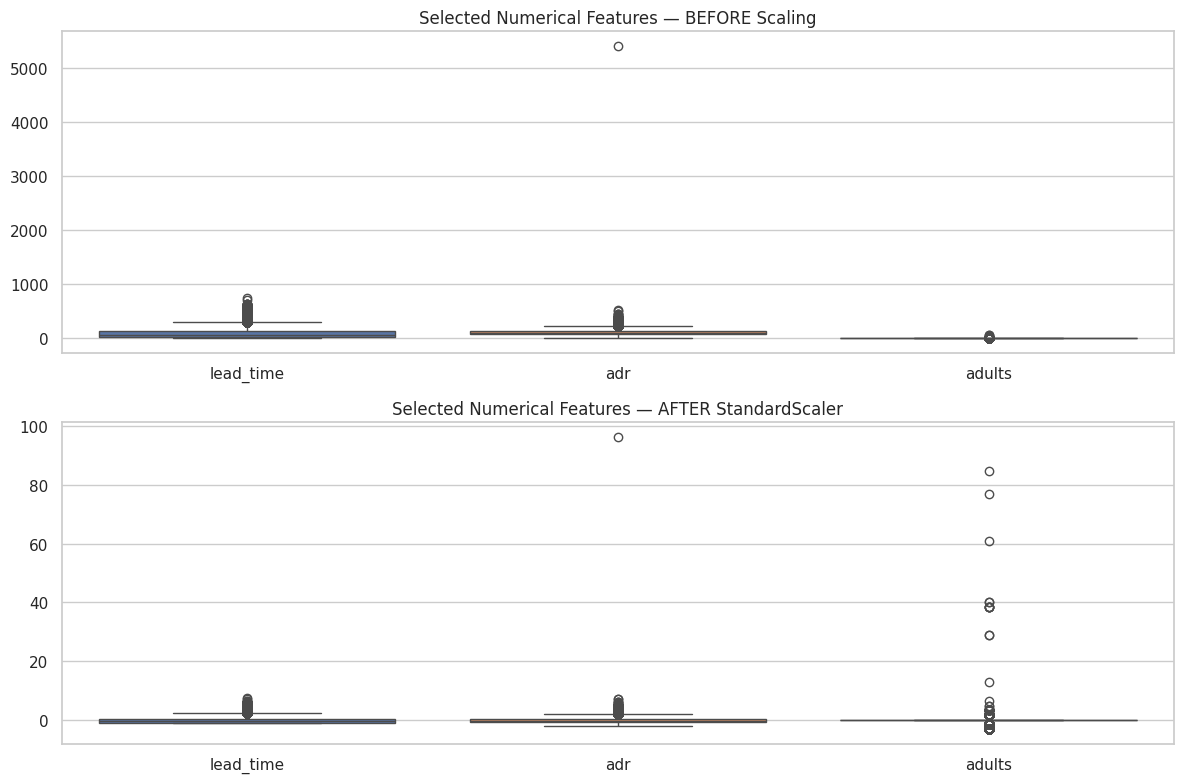

In [15]:
scale_demo_cols = [c for c in ["lead_time", "adr", "adults"] if c in df_clean.columns]
scale_demo = df_clean[scale_demo_cols].copy()
scale_demo = scale_demo.fillna(scale_demo.median(numeric_only=True))
demo_scaler = StandardScaler()
scaled_demo = pd.DataFrame(
    demo_scaler.fit_transform(scale_demo),
    columns=scale_demo_cols,
    index=scale_demo.index
)

fig, axes = plt.subplots(2, 1, figsize=(12,8))
sns.boxplot(data=scale_demo, ax=axes[0])
axes[0].set_title("Selected Numerical Features — BEFORE Scaling")
sns.boxplot(data=scaled_demo, ax=axes[1])
axes[1].set_title("Selected Numerical Features — AFTER StandardScaler")
plt.tight_layout()
plt.show()


## 4. Shared preprocessing tools for Regression and Classification

We choose a small, explainable set of predictors. We exclude `reservation_status` and `reservation_status_date` because they describe the final outcome of a booking and would leak information into a cancellation prediction. We also exclude `company` and `agent` due to their very high missingness / identifier-like nature.

`ColumnTransformer` applies median imputation + scaling to numeric columns and most-frequent imputation + One-Hot Encoding to categorical columns. These operations are fitted only on each training split.

In [16]:
candidate_features = [
    "hotel", "lead_time", "arrival_date_year", "arrival_date_month",
    "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "meal", "country",
    "market_segment", "distribution_channel", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled",
    "reserved_room_type", "assigned_room_type", "booking_changes",
    "deposit_type", "customer_type", "required_car_parking_spaces",
    "total_of_special_requests"
]
feature_cols = [c for c in candidate_features if c in df_clean.columns]

categorical_features = df_clean[feature_cols].select_dtypes(
    include=["object", "category"]
).columns.tolist()
numeric_features = [c for c in feature_cols if c not in categorical_features]

print("Features used:", feature_cols)
print("\\nNumerical features:", numeric_features)
print("\\nCategorical features:", categorical_features)

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])


Features used: ['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'customer_type', 'required_car_parking_spaces', 'total_of_special_requests']
\nNumerical features: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests']
\nCategorical features: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserv

## 5. Regression — Linear Regression

**Question:** Can we predict the average daily rate (`adr`) of a hotel booking?

- Target: `adr` (continuous numerical value)
- Algorithm: Linear Regression
- Metrics: MSE, RMSE, and R²
- We exclude rows where ADR is missing after invalid negative values were converted to missing.
- We split before fitting preprocessing to avoid data leakage.

In [17]:
regression_data = df_clean.dropna(subset=["adr"]).copy()
X_reg = regression_data[feature_cols]
y_reg = regression_data["adr"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

regression_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

regression_model.fit(X_train_reg, y_train_reg)
y_pred_reg = regression_model.predict(X_test_reg)

mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"Training rows: {len(X_train_reg):,}")
print(f"Testing rows: {len(X_test_reg):,}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")


Training rows: 69,916
Testing rows: 17,479
MSE:  998.010
RMSE: 31.591
R²:   0.639


### 5.1 Regression visualization — Actual vs Predicted

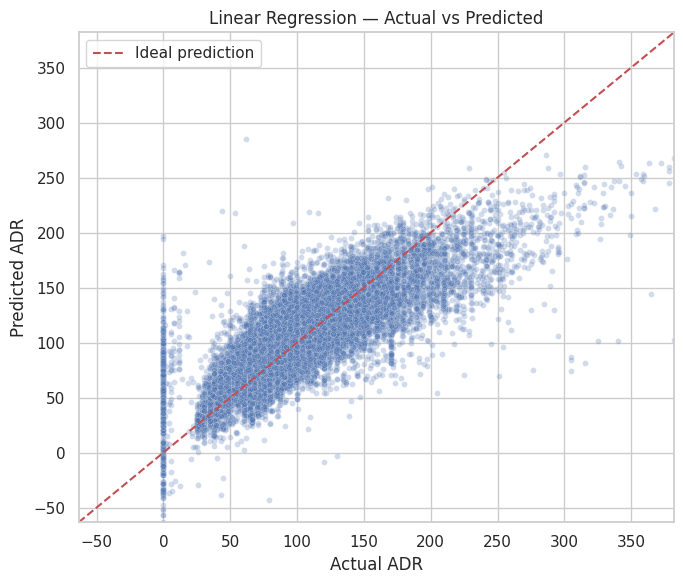

In [18]:
plt.figure(figsize=(7,6))
sns.scatterplot(x=y_test_reg, y=y_pred_reg, alpha=0.25, s=18)
lims = [
    min(float(y_test_reg.min()), float(np.min(y_pred_reg))),
    max(float(y_test_reg.max()), float(np.max(y_pred_reg)))
]
plt.plot(lims, lims, "r--", label="Ideal prediction")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Actual ADR")
plt.ylabel("Predicted ADR")
plt.title("Linear Regression — Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()


### 5.2 Regression residuals

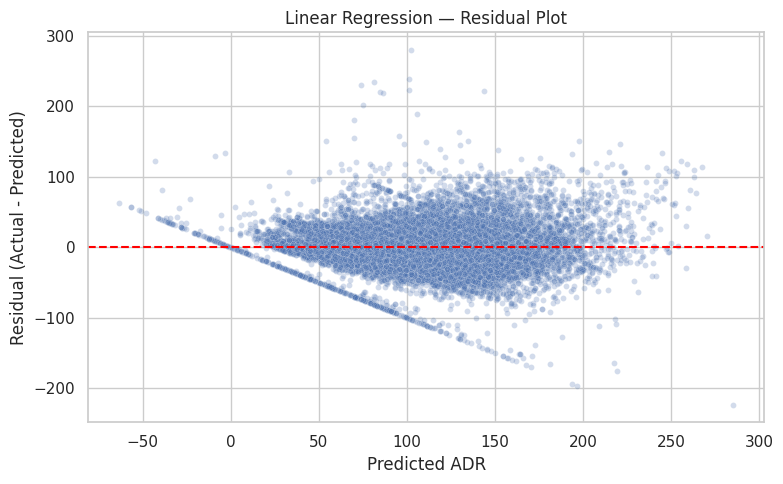

In [19]:
residuals = y_test_reg - y_pred_reg
plt.figure(figsize=(8,5))
sns.scatterplot(x=y_pred_reg, y=residuals, alpha=0.25, s=18)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted ADR")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Linear Regression — Residual Plot")
plt.tight_layout()
plt.show()


**How to interpret:** lower MSE and RMSE indicate smaller prediction errors. R² describes the proportion of target variance explained by the model on the test set. The actual-vs-predicted plot should place good predictions near the diagonal; residuals should ideally be scattered around zero without a strong pattern.

## 6. Classification — Logistic Regression

**Question:** Can we predict whether a booking will be canceled?

- Target: `is_canceled` (0 = not canceled, 1 = canceled)
- Algorithm: Logistic Regression
- Metrics: Accuracy, Confusion Matrix, Precision, Recall, and ROC-AUC
- `reservation_status` and `reservation_status_date` are excluded because they reveal information about the final booking outcome.

In [20]:
classification_data = df_clean.dropna(subset=["is_canceled"]).copy()
X_clf = classification_data[feature_cols]
y_clf = classification_data["is_canceled"].astype(int)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

classification_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, solver="liblinear"))
])

classification_model.fit(X_train_clf, y_train_clf)
y_pred_clf = classification_model.predict(X_test_clf)
y_prob_clf = classification_model.predict_proba(X_test_clf)[:, 1]

accuracy = accuracy_score(y_test_clf, y_pred_clf)
precision = precision_score(y_test_clf, y_pred_clf, zero_division=0)
recall = recall_score(y_test_clf, y_pred_clf, zero_division=0)
roc_auc = roc_auc_score(y_test_clf, y_prob_clf)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")
print("\\nClassification report:")
print(classification_report(y_test_clf, y_pred_clf, zero_division=0))


Accuracy:  0.792
Precision: 0.673
Recall:    0.474
ROC-AUC:   0.842
\nClassification report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86     12675
           1       0.67      0.47      0.56      4805

    accuracy                           0.79     17480
   macro avg       0.75      0.69      0.71     17480
weighted avg       0.78      0.79      0.78     17480



### 6.1 Confusion Matrix

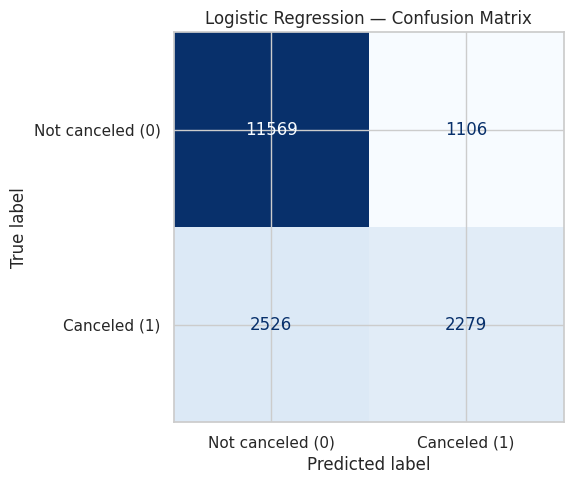

True Negatives (TN): 11,569
False Positives (FP): 1,106
False Negatives (FN): 2,526
True Positives (TP): 2,279


In [21]:
cm = confusion_matrix(y_test_clf, y_pred_clf)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not canceled (0)", "Canceled (1)"]
)
fig, ax = plt.subplots(figsize=(6,5))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN): {tn:,}")
print(f"False Positives (FP): {fp:,}")
print(f"False Negatives (FN): {fn:,}")
print(f"True Positives (TP): {tp:,}")


### 6.2 ROC Curve

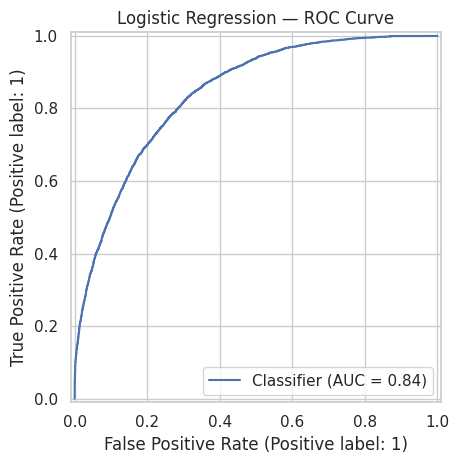

In [22]:
RocCurveDisplay.from_predictions(y_test_clf, y_prob_clf)
plt.title("Logistic Regression — ROC Curve")
plt.tight_layout()
plt.show()


**How to interpret:** precision answers: among bookings predicted as canceled, how many really canceled? Recall answers: among all bookings that really canceled, how many did the model find? The confusion matrix shows the four types of correct and incorrect predictions.

## 7. Clustering — K-Means

**Question:** Can we discover groups of similar bookings without using the cancellation label?

For clustering we deliberately do **not** use `is_canceled` or `adr` as labels. We select a small set of booking-behaviour features, impute missing values, scale them, use the Elbow Method to inspect candidate K values, and calculate the Silhouette Score.

To keep the run practical in Colab, we use a reproducible sample of up to 10,000 bookings.

In [23]:
cluster_features = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "required_car_parking_spaces", "total_of_special_requests"
]
cluster_features = [c for c in cluster_features if c in df_clean.columns]

cluster_sample = df_clean[cluster_features].sample(
    n=min(10000, len(df_clean)), random_state=RANDOM_STATE
).copy()

cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()
X_cluster_imputed = cluster_imputer.fit_transform(cluster_sample)
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster_imputed)

print("Clustering sample shape:", X_cluster_scaled.shape)
print("Features used:", cluster_features)


Clustering sample shape: (10000, 11)
Features used: ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests']


### 7.1 Elbow Method — choosing K

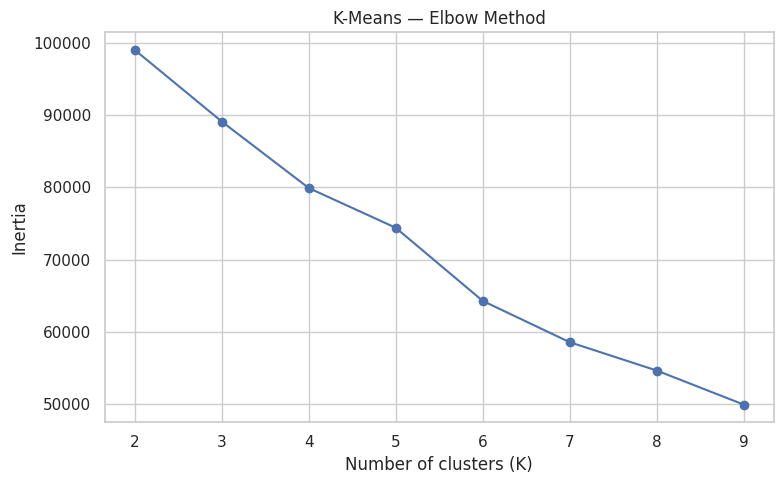

In [24]:
inertias = []
k_values = range(2, 10)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means — Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


**Choose K after inspecting the elbow plot.** The elbow is the point after which adding more clusters produces a smaller reduction in inertia. The code below uses K=4 as a starting choice; if the plot suggests a clearer elbow elsewhere, change `chosen_k` before running the next cell.

In [25]:
chosen_k = 4  # Change this after reviewing the Elbow plot

kmeans = KMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

# Silhouette can be computationally expensive; calculate it on a reproducible subset.
silhouette_sample_size = min(3000, len(X_cluster_scaled))
silhouette_value = silhouette_score(
    X_cluster_scaled,
    cluster_labels,
    sample_size=silhouette_sample_size,
    random_state=RANDOM_STATE
)

print("Chosen K:", chosen_k)
print(f"Silhouette Score (sample): {silhouette_value:.3f}")


Chosen K: 4
Silhouette Score (sample): 0.227


### 7.2 Visualize clusters using PCA (2 dimensions)

PCA is used only to project the scaled features into two dimensions for visualization. The K-Means model was fitted using the selected scaled features, not just the two plotted components.

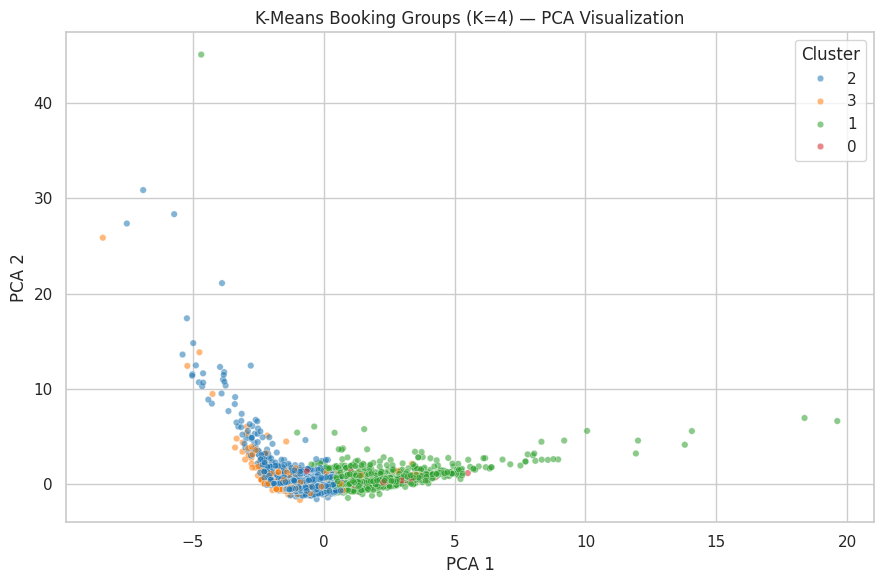

,booking_count
Cluster,
0,107
1,2828
2,6224
3,841


In [26]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
cluster_2d = pca.fit_transform(X_cluster_scaled)

cluster_plot = pd.DataFrame({
    "PCA 1": cluster_2d[:, 0],
    "PCA 2": cluster_2d[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(9,6))
sns.scatterplot(
    data=cluster_plot, x="PCA 1", y="PCA 2",
    hue="Cluster", palette="tab10", alpha=0.55, s=22
)
plt.title(f"K-Means Booking Groups (K={chosen_k}) — PCA Visualization")
plt.tight_layout()
plt.show()

display(cluster_plot["Cluster"].value_counts().sort_index().rename("booking_count").to_frame())


### 7.3 Describe the clusters

These summaries use the original feature units for easier interpretation.

In [27]:
cluster_summary = cluster_sample.copy()
cluster_summary["cluster"] = cluster_labels
display(cluster_summary.groupby("cluster").mean().round(2))


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,required_car_parking_spaces,total_of_special_requests
cluster,,,,,,,,,,,
0,94.55,1.30,3.08,2.0,0.12,1.01,0.02,0.00,0.79,0.14,1.54
1,167.66,1.86,4.46,2.0,0.22,0.00,0.04,0.02,0.43,0.00,0.79
2,45.48,0.65,1.86,1.8,0.10,0.00,0.03,0.21,0.19,0.00,0.63
3,50.40,0.85,2.28,1.9,0.20,0.00,0.01,0.48,0.33,1.00,0.83


## 8. Ten useful questions about this dataset — with answers

The answers below are calculated from the uploaded CSV when you run the cell. They are not guessed or hard-coded. These questions help explain the dataset and connect the analysis to hotel-booking decisions.

In [28]:
# Q1. How many bookings and features are in the dataset?
q1 = f"The dataset contains {df_raw.shape[0]:,} booking records and {df_raw.shape[1]} columns."

# Q2. Which column has the most missing values?
missing_counts_all = df_raw.isna().sum()
most_missing_col = missing_counts_all.idxmax()
q2 = f"'{most_missing_col}' has the most missing values: {missing_counts_all.max():,} ({missing_counts_all.max()/len(df_raw):.1%} of rows)."

# Q3. How many exact duplicate rows are there?
q3 = f"There are {duplicates_before:,} exact duplicate rows ({duplicates_before/len(df_raw):.1%} of the raw dataset)."

# Q4. What percentage of bookings were canceled?
cancel_rate = df_raw["is_canceled"].mean() * 100
q4 = f"{cancel_rate:.2f}% of bookings were canceled."

# Q5. Which hotel type has the higher cancellation rate?
hotel_rates = df_raw.groupby("hotel")["is_canceled"].mean() * 100
higher_hotel = hotel_rates.idxmax()
q5 = f"{higher_hotel} has the higher cancellation rate ({hotel_rates.max():.2f}%), compared with {hotel_rates.min():.2f}% for the other hotel type."

# Q6. What is the median lead time?
median_lead = df_raw["lead_time"].median()
q6 = f"The median lead time is {median_lead:.0f} days. Half of the bookings were made at or below this value."

# Q7. What is the median ADR among valid non-negative ADR records?
valid_adr = df_clean["adr"].dropna()
q7 = f"The median ADR after excluding invalid negative values is {valid_adr.median():.2f}."

# Q8. Which market segment has the most bookings?
if "market_segment" in df_raw.columns:
    top_segment = df_raw["market_segment"].value_counts().idxmax()
    top_segment_count = int(df_raw["market_segment"].value_counts().max())
    q8 = f"'{top_segment}' is the most frequent market segment, with {top_segment_count:,} bookings."
else:
    q8 = "The market_segment column is not available in this file."

# Q9. What is the most common customer type?
if "customer_type" in df_raw.columns:
    top_customer = df_raw["customer_type"].value_counts().idxmax()
    top_customer_count = int(df_raw["customer_type"].value_counts().max())
    q9 = f"'{top_customer}' is the most common customer type, with {top_customer_count:,} bookings."
else:
    q9 = "The customer_type column is not available in this file."

# Q10. What is the average number of special requests?
avg_requests = df_raw["total_of_special_requests"].mean()
q10 = f"The average is {avg_requests:.2f} special requests per booking."

qa = [
    ("1. How many bookings and features are in the dataset?", q1),
    ("2. Which column has the most missing values?", q2),
    ("3. How many exact duplicate rows are there?", q3),
    ("4. What percentage of bookings were canceled?", q4),
    ("5. Which hotel type has the higher cancellation rate?", q5),
    ("6. What is the median lead time?", q6),
    ("7. What is the median ADR among valid non-negative ADR records?", q7),
    ("8. Which market segment has the most bookings?", q8),
    ("9. What is the most common customer type?", q9),
    ("10. What is the average number of special requests?", q10),
]

for question, answer in qa:
    display(Markdown(f"**{question}**\\n\\n**Answer:** {answer}"))


**1. How many bookings and features are in the dataset?**\n\n**Answer:** The dataset contains 119,390 booking records and 32 columns.

**2. Which column has the most missing values?**\n\n**Answer:** 'company' has the most missing values: 112,593 (94.3% of rows).

**3. How many exact duplicate rows are there?**\n\n**Answer:** There are 31,994 exact duplicate rows (26.8% of the raw dataset).

**4. What percentage of bookings were canceled?**\n\n**Answer:** 37.04% of bookings were canceled.

**5. Which hotel type has the higher cancellation rate?**\n\n**Answer:** City Hotel has the higher cancellation rate (41.73%), compared with 27.76% for the other hotel type.

**6. What is the median lead time?**\n\n**Answer:** The median lead time is 69 days. Half of the bookings were made at or below this value.

**7. What is the median ADR among valid non-negative ADR records?**\n\n**Answer:** The median ADR after excluding invalid negative values is 98.10.

**8. Which market segment has the most bookings?**\n\n**Answer:** 'Online TA' is the most frequent market segment, with 56,477 bookings.

**9. What is the most common customer type?**\n\n**Answer:** 'Transient' is the most common customer type, with 89,613 bookings.

**10. What is the average number of special requests?**\n\n**Answer:** The average is 0.57 special requests per booking.

## 9. Final project results summary

This cell collects the main metrics from the three machine-learning tasks into one table.

In [29]:
final_results = pd.DataFrame([
    {"Task": "Regression — Linear Regression", "Metric": "MSE", "Value": mse},
    {"Task": "Regression — Linear Regression", "Metric": "RMSE", "Value": rmse},
    {"Task": "Regression — Linear Regression", "Metric": "R²", "Value": r2},
    {"Task": "Classification — Logistic Regression", "Metric": "Accuracy", "Value": accuracy},
    {"Task": "Classification — Logistic Regression", "Metric": "Precision", "Value": precision},
    {"Task": "Classification — Logistic Regression", "Metric": "Recall", "Value": recall},
    {"Task": "Classification — Logistic Regression", "Metric": "ROC-AUC", "Value": roc_auc},
    {"Task": "Clustering — K-Means", "Metric": "Chosen K", "Value": chosen_k},
    {"Task": "Clustering — K-Means", "Metric": "Silhouette Score (sample)", "Value": silhouette_value},
])
display(final_results.round(4))


,Task,Metric,Value
0,Regression — Linear Regression,MSE,998.0104
1,Regression — Linear Regression,RMSE,31.5913
2,Regression — Linear Regression,R²,0.6389
3,Classification — Logistic Regression,Accuracy,0.7922
4,Classification — Logistic Regression,Precision,0.6733
5,Classification — Logistic Regression,Recall,0.4743
6,Classification — Logistic Regression,ROC-AUC,0.8416
7,Clustering — K-Means,Chosen K,4.0000
8,Clustering — K-Means,Silhouette Score (sample),0.2270


## 10. Final notes and limitations

- The results depend on the uploaded CSV and the train/test split; record the metrics produced by your own run in the report.
- Linear Regression is a baseline model. Its performance may be affected by non-linear relationships and extreme ADR values.
- Logistic Regression is evaluated using several metrics because accuracy alone can hide weak performance on one class.
- K-Means is unsupervised: it does not use cancellation labels. The Silhouette Score is an internal measure of cluster separation, not a prediction accuracy.
- The chosen K should be justified from the Elbow plot and cluster interpretation, not selected only because it gives a preferred score.
- Before final submission, save the notebook with all outputs and include the Colab link in the PDF report, as required by the project manual.

**End of complete capstone notebook.**